In [14]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from data_preprocessing import load_ratings, load_movies, build_dataset, GENRE_NAMES

In [15]:
ratings = load_ratings('../data/ml-100k')
movies = load_movies('../data/ml-100k')

print(ratings.shape, movies.shape)
ratings.head()

(100000, 4) (1682, 24)


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64


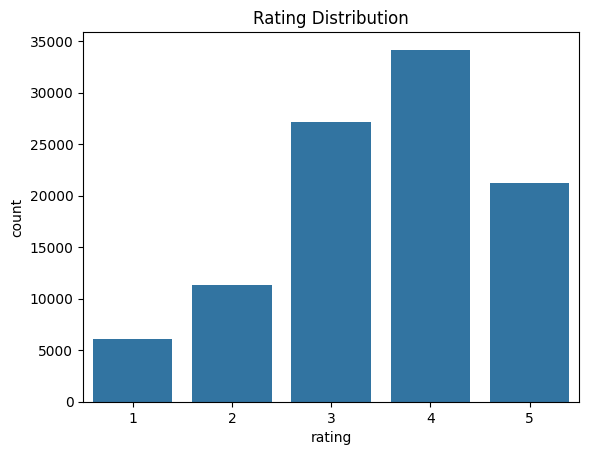

In [16]:
print(ratings['rating'].value_counts().sort_index())

sns.countplot(data=ratings, x='rating')
plt.title('Rating Distribution')
plt.show()


In [17]:
print(ratings.groupby('user_id').size().describe())
print(ratings.groupby('item_id').size().describe())

count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
dtype: float64
count    1682.000000
mean       59.453032
std        80.383846
min         1.000000
25%         6.000000
50%        27.000000
75%        80.000000
max       583.000000
dtype: float64


In [18]:
counts = ratings.groupby('item_id').size().sort_values(ascending=False).head(10)

for item_id, number_of_ratings in counts.items():
    title = movies.loc[movies['item_id'] == item_id, 'title'].values[0]
    print(number_of_ratings, title)


583 Star Wars (1977)
509 Contact (1997)
508 Fargo (1996)
507 Return of the Jedi (1983)
485 Liar Liar (1997)
481 English Patient, The (1996)
478 Scream (1996)
452 Toy Story (1995)
431 Air Force One (1997)
429 Independence Day (ID4) (1996)


unknown          2
Fantasy         22
Film-Noir       24
Western         27
Animation       42
Documentary     50
Musical         56
Mystery         61
War             71
Horror          92
Sci-Fi         101
Crime          109
Children's     122
Adventure      135
Romance        247
Action         251
Thriller       251
Comedy         505
Drama          725
dtype: int64


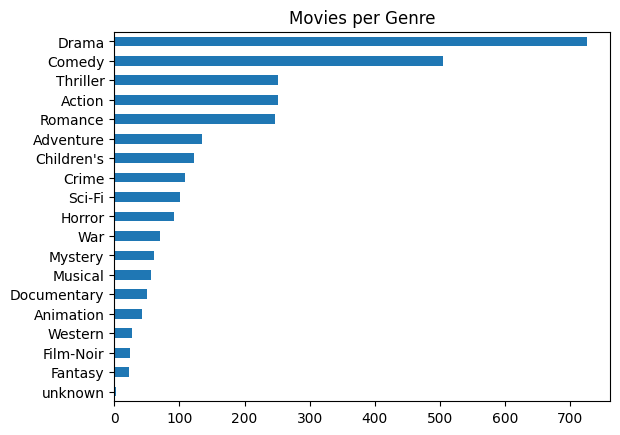

In [19]:
genre_counts = movies[GENRE_NAMES].sum().sort_values()
print(genre_counts)

genre_counts.plot(kind='barh')
plt.title('Movies per Genre')
plt.show()


In [20]:
from lightfm import LightFM
from lightfm.cross_validation import random_train_test_split
from lightfm.evaluation import precision_at_k, recall_at_k, auc_score

dataset, interactions, item_features = build_dataset(ratings, movies)
print(interactions.shape, item_features.shape)

train, test = random_train_test_split(
    interactions, test_percentage=0.2, random_state=np.random.RandomState(42)
)

(943, 1682) (1682, 1701)


In [21]:
cf_model = LightFM(loss='warp', no_components=30, random_state=42)
cf_model.fit(train, epochs=30, num_threads=2)

cf_precision = precision_at_k(cf_model, test, train_interactions=train, k=5).mean()
cf_recall = recall_at_k(cf_model, test, train_interactions=train, k=5).mean()
cf_auc = auc_score(cf_model, test, train_interactions=train).mean()

print('Precision@5:', cf_precision)
print('Recall@5:', cf_recall)
print('AUC:', cf_auc)

Precision@5: 0.2549403
Recall@5: 0.15160898344924187
AUC: 0.9355209


In [22]:
hybrid_model = LightFM(loss='warp', no_components=30, random_state=42)
hybrid_model.fit(train, item_features=item_features, epochs=30, num_threads=2)

hy_precision = precision_at_k(hybrid_model, test, train_interactions=train, k=5, item_features=item_features).mean()
hy_recall = recall_at_k(hybrid_model, test, train_interactions=train, k=5, item_features=item_features).mean()
hy_auc = auc_score(hybrid_model, test, train_interactions=train, item_features=item_features).mean()

print('Precision@5:', hy_precision)
print('Recall@5:', hy_recall)
print('AUC:', hy_auc)

Precision@5: 0.2592834
Recall@5: 0.14234517827108387
AUC: 0.9333993


             Collaborative  Hybrid
Precision@5         0.2549  0.2593
Recall@5            0.1516  0.1423
AUC                 0.9355  0.9334


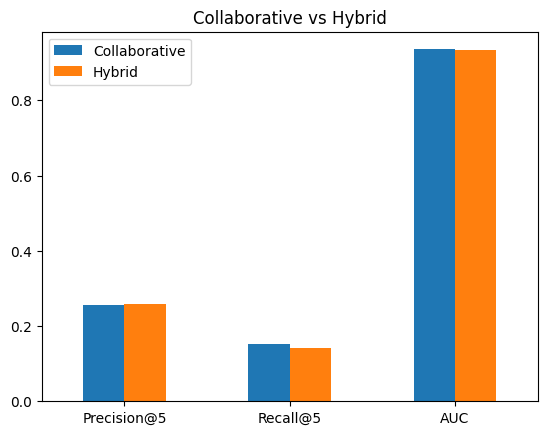

In [23]:
compare = pd.DataFrame(
    {
        'Collaborative': [cf_precision, cf_recall, cf_auc],
        'Hybrid': [hy_precision, hy_recall, hy_auc],
    },
    index=['Precision@5', 'Recall@5', 'AUC']
)
print(compare.round(4))

compare.plot(kind='bar')
plt.title('Collaborative vs Hybrid')
plt.xticks(rotation=0)
plt.show()

In [24]:
user_id_map, user_feature_map, item_id_map, item_feature_map = dataset.mapping()

reverse_item_map = {}
for real_id, internal_id in item_id_map.items():
    reverse_item_map[internal_id] = real_id

titles = dict(zip(movies['item_id'], movies['title']))

user_id = 1
scores = hybrid_model.predict(user_id_map[user_id], np.arange(len(item_id_map)), item_features=item_features)

liked = ratings[(ratings['user_id'] == user_id) & (ratings['rating'] >= 4)]
already_liked = set(liked['item_id'])

print('Movies user already liked (sample):')
for item_id in list(already_liked)[:5]:
    print('  -', titles[item_id])

print('Top 5 recommendations:')
count = 0
for position in np.argsort(-scores):
    real_id = reverse_item_map[position]
    if real_id in already_liked:
        continue
    print('  -', titles[real_id])
    count = count + 1
    if count == 5:
        break

Movies user already liked (sample):
  - Toy Story (1995)
  - Four Rooms (1995)
  - Shanghai Triad (Yao a yao yao dao waipo qiao) (1995)
  - Twelve Monkeys (1995)
  - Dead Man Walking (1995)
Top 5 recommendations:
  - Trainspotting (1996)
  - Clockwork Orange, A (1971)
  - Get Shorty (1995)
  - Jackie Chan's First Strike (1996)
  - One Flew Over the Cuckoo's Nest (1975)


In [25]:
%cd ../src
!python train_model.py
!python predict.py
%cd ../notebook

/content/movie-recommendation-lightfm/src
Interactions matrix shape: (943, 1682)
Collaborative -> Precision@5: 0.2495 | Recall@5: 0.1467 | AUC: 0.9356
Hybrid        -> Precision@5: 0.2571 | Recall@5: 0.1440 | AUC: 0.9338
Best model: Hybrid
Model saved at ../models/recommender.pkl
Movies user 1 already liked (sample):
  - Toy Story (1995)
  - Four Rooms (1995)
  - Shanghai Triad (Yao a yao yao dao waipo qiao) (1995)
  - Twelve Monkeys (1995)
  - Dead Man Walking (1995)
Top 5 recommendations:
  - Trainspotting (1996)
  - Clockwork Orange, A (1971)
  - One Flew Over the Cuckoo's Nest (1975)
  - Heathers (1989)
  - Get Shorty (1995)
/content/movie-recommendation-lightfm/notebook
